**Detect Malaria in blod cells**

In [1]:
import os
import datetime
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow_datasets as tfds
from tensorflow.keras.layers import InputLayer, Conv2D, BatchNormalization, MaxPool2D, Flatten, Dense, Dropout, Rescaling, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Sequential
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.regularizers import L2
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
)
from tensorflow.keras.metrics import (
    BinaryAccuracy,
    Precision,
    Recall,
    AUC,
    TruePositives,
    FalsePositives,
    TrueNegatives,
    FalseNegatives,
)
import warnings
warnings.filterwarnings("ignore")

In [2]:
!pip install wandb

In [3]:
import wandb
from wandb.integration.keras import WandbMetricsLogger, WandbModelCheckpoint

### Configuration

In [4]:
CONFIGURATION = {
    "SEED": 42,
    "LEARNING_RATE": 0.001,
    "N_EPOCHS": 24,
    "BATCH_SIZE": 32,
    "DROPOUT_RATE": 0.0,
    "IM_SIZE": 224,
    "REGULARIZATION_RATE": 0.0,
    "N_FILTERS": 6,
    "KERNEL_SIZE": 3,
    "N_STRIDES": 1,
    "POOL_SIZE": 2,
    "N_DENSE_1": 100,
    "N_DENSE_2": 10,
}

In [5]:
tf.keras.utils.set_random_seed(CONFIGURATION["SEED"])
IMG_SIZE = CONFIGURATION["IM_SIZE"]
BATCH_SIZE = CONFIGURATION["BATCH_SIZE"]
AUTOTUNE = tf.data.AUTOTUNE

In [6]:
OUTPUT_DIR = "malaria_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

### W&B LOGIN AND INITIALIZATION

In [7]:
wandb.login()

run = wandb.init(
    entity="vinaybelieve55-rgukt-ongole",
    project="Malaria-Detection",
    name=f"lenet-{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}",
    config=CONFIGURATION,
    job_type="train",
    tags=["tensorflow", "cnn", "malaria"],
)

print("W&B run:", run.url)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: vinaybelieve55 (vinaybelieve55-rgukt-ongole) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B run: https://wandb.ai/vinaybelieve55-rgukt-ongole/Malaria-Detection/runs/y0xiedi9


# Data preparation

## Data loading

In [8]:
!pip install -q importlib_resources

In [9]:
(train_dataset, val_dataset, test_dataset), dataset_info = tfds.load(
    "malaria",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    with_info=True,
    as_supervised=True,
    shuffle_files=False,
)

In [10]:
CLASS_NAMES = dataset_info.features["label"].names

In [11]:
# for data in train_dataset[0].take(1):
#     print(data)
#     break

## Data visualization

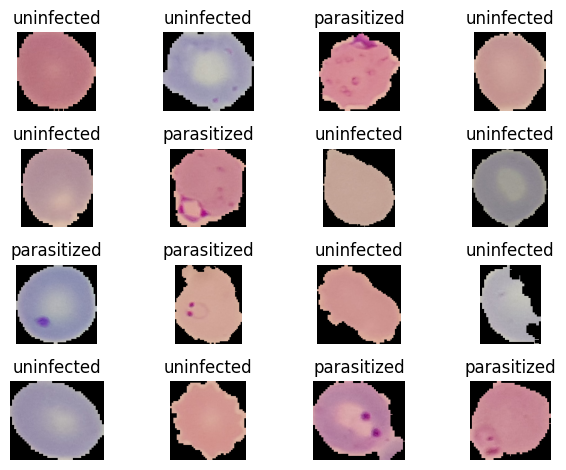

In [12]:
for i, (image, label) in enumerate(train_dataset.take(16)):
    ax = plt.subplot(4, 4, i + 1)

    plt.imshow(image)
    plt.title(dataset_info.features['label'].int2str(label))
    plt.axis('off')
plt.tight_layout()
plt.show()

## Data Preprocessing

In [13]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)

    label = tf.reshape(tf.cast(label, tf.float32),(1,))
    return image, label

In [14]:
train_dataset = (
    train_dataset
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .shuffle(1024, seed=CONFIGURATION["SEED"], reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [15]:
train_dataset, val_dataset

(<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))>,
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))>)

## Data Augmentation

In [16]:
# def visualize(original, augmented):
#     plt.subplot(1,2,1)
#     plt.imshow(original)

#     plt.subplot(1,2,2)
#     plt.imshow(augmented)
#     plt.show()

In [17]:
# original_image, original_label = next(iter(train_dataset))

In [18]:
# augmented_image = tf.image.rot90(original_image)
# visualize(original_image, augmented_image)

In [19]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(factor = (0.25, 0.2501)),
    tf.keras.layers.RandomFlip(mode="horizontal"),
    tf.keras.layers.RandomContrast(factor=0.1),
], name = "data_augmentation")

# Model Creation and Training

In [20]:
def build_model(config):
    return Sequential(
        [
            Input(shape=(config["IM_SIZE"], config["IM_SIZE"], 3)),

            Rescaling(1.0 / 255),
            data_augmentation,

            Conv2D(
                filters=config["N_FILTERS"],
                kernel_size=config["KERNEL_SIZE"],
                strides=config["N_STRIDES"],
                padding="valid",
                activation="relu",
                kernel_regularizer=L2(config["REGULARIZATION_RATE"]),
            ),
            BatchNormalization(),
            MaxPool2D(
                pool_size=config["POOL_SIZE"],
                strides=config["N_STRIDES"] * 2,
            ),
            Dropout(rate=config["DROPOUT_RATE"]),

            Conv2D(
                filters=config["N_FILTERS"] * 2 + 4,
                kernel_size=config["KERNEL_SIZE"],
                strides=config["N_STRIDES"],
                padding="valid",
                activation="relu",
                kernel_regularizer=L2(config["REGULARIZATION_RATE"]),
            ),
            BatchNormalization(),
            MaxPool2D(
                pool_size=config["POOL_SIZE"],
                strides=config["N_STRIDES"] * 2,
            ),

            Flatten(),

            Dense(
                config["N_DENSE_1"],
                activation="relu",
                kernel_regularizer=L2(config["REGULARIZATION_RATE"]),
            ),
            BatchNormalization(),
            Dropout(rate=config["DROPOUT_RATE"]),

            Dense(
                config["N_DENSE_2"],
                activation="relu",
                kernel_regularizer=L2(config["REGULARIZATION_RATE"]),
            ),
            BatchNormalization(),

            Dense(1, activation="sigmoid"),
        ],
        name="Malaria_LeNet",
    )


lenet_model = build_model(CONFIGURATION)
lenet_model.summary()

Model: "Malaria_LeNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 6)    │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 6)    │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 111, 111, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 16)   │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 46656)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     4,665,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 10)             │            40 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,668,297 (17.81 MB)

 Trainable params: 4,668,033 (17.81 MB)

 Non-trainable params: 264 (1.03 KB)

## Compile Model

In [21]:
metrics = [
    TruePositives(name="tp"),
    FalsePositives(name="fp"),
    TrueNegatives(name="tn"),
    FalseNegatives(name="fn"),
    BinaryAccuracy(name="accuracy"),
    Precision(name="precision"),
    Recall(name="recall"),
    AUC(name="auc"),
]

In [22]:
optimizer = Adam(learning_rate=CONFIGURATION["LEARNING_RATE"])
loss = BinaryCrossentropy()

lenet_model.compile(optimizer, loss, metrics = metrics)

## Callbacks

In [23]:
# run_time = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
# log_dir = os.path.join(OUTPUT_DIR, "logs", run_time)
best_model_path = os.path.join(OUTPUT_DIR, "best_malaria_model.keras")

In [24]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        verbose=1,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        best_model_path,
        monitor='val_loss',
        verbose=1,
        save_best_only=True,
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.1,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
    # tf.keras.callbacks.TensorBoard(log_dir, update_freq=1)
    WandbMetricsLogger(log_freq="epoch")
]

## Train the model

In [25]:
history = lenet_model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs=CONFIGURATION["N_EPOCHS"],
    callbacks = callbacks,
    verbose=1,
)

Epoch 1/24
689/689 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7238 - auc: 0.7912 - fn: 1302.0218 - fp: 1437.6546 - loss: 0.5574 - precision: 0.7215 - recall: 0.7405 - tn: 4057.1611 - tp: 4243.1597
Epoch 1: val_loss improved from None to 0.42027, saving model to malaria_outputs/best_malaria_model.keras

Epoch 1: finished saving model to malaria_outputs/best_malaria_model.keras
689/689 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.7987 - auc: 0.8799 - fn: 2107.0000 - fp: 2330.0000 - loss: 0.4367 - precision: 0.7933 - recall: 0.8093 - tn: 8669.0000 - tp: 8940.0000 - val_accuracy: 0.8233 - val_auc: 0.8950 - val_fn: 374.0000 - val_fp: 113.0000 - val_loss: 0.4203 - val_precision: 0.8959 - val_recall: 0.7223 - val_tn: 1296.0000 - val_tp: 973.0000 - learning_rate: 0.0010
Epoch 2/24
688/689 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9046 - auc: 0.9589 - fn: 458.7340 - fp: 571.5581 - loss: 0.2550 - precision: 0.8985 - recall: 0.9146 - tn: 4913.2035 - tp: 5080.5044
Epoch 2: val_loss 

## Visualizations

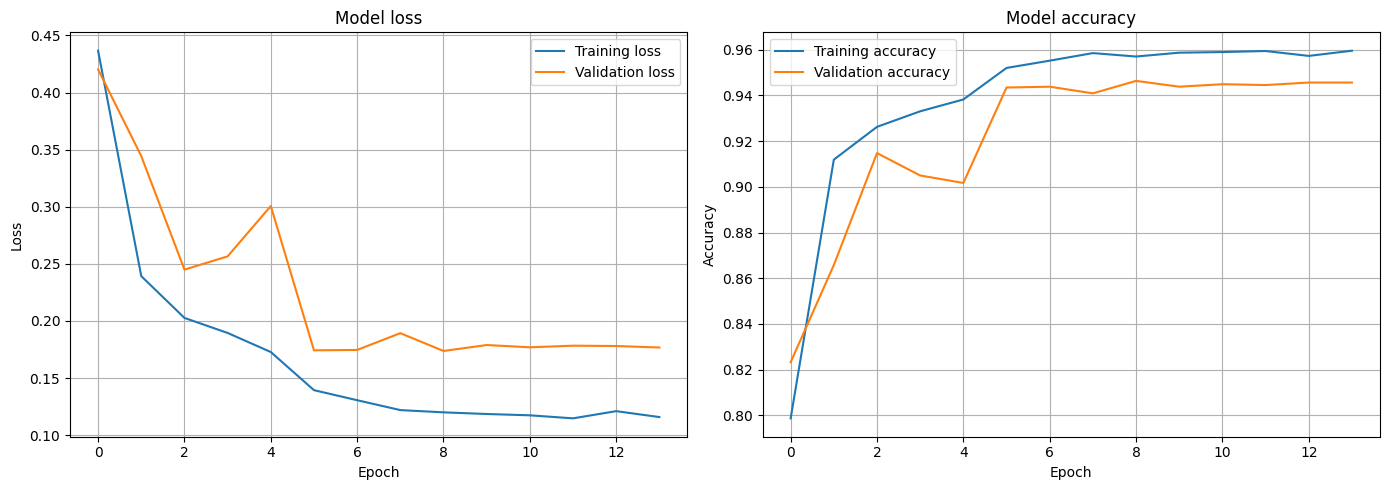

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Model loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(
    history.history["val_accuracy"],
    label="Validation accuracy",
)
axes[1].set_title("Model accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
# %load_ext tensorboard

In [28]:
# tensorboard --logdir './logs'

# **Model Evaluation and Testing**

## Load best model

In [29]:
lenet_model = tf.keras.models.load_model(best_model_path)

## Evaluate model

In [30]:
test_results = lenet_model.evaluate(test_dataset, return_dict = True, verbose = 1)
for name, value in test_results.items():
    print(f"{name}: {value:.4f}")

87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9416 - auc: 0.9754 - fn: 43.0000 - fp: 118.0000 - loss: 0.1972 - precision: 0.9192 - recall: 0.9690 - tn: 1253.0000 - tp: 1342.0000
accuracy: 0.9416
auc: 0.9754
fn: 43.0000
fp: 118.0000
loss: 0.1972
precision: 0.9192
recall: 0.9690
tn: 1253.0000
tp: 1342.0000


In [31]:
def parasite_or_not(x):
    if x<0.5:
        return str('P')
    else:
        return str('U')

In [32]:
parasite_or_not(lenet_model.predict(test_dataset.take(1))[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


'U'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


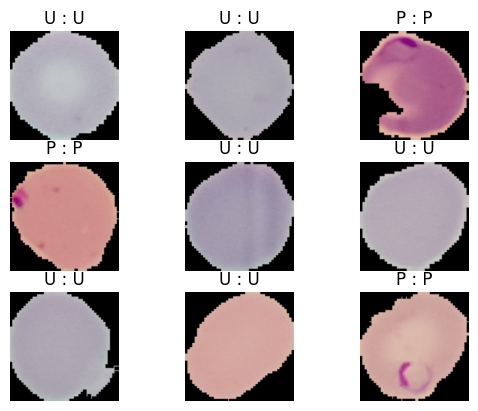

In [33]:
for i, (image_batch, label_batch) in enumerate(test_dataset.take(9)):
  ax = plt.subplot(3, 3, i + 1)

  single_image = image_batch[0]
  single_label = label_batch[0].numpy()
  if single_image.dtype == 'float32' and single_image.numpy().max() > 1.0:
      img_to_show = single_image.numpy() / 255.0
  else:
      img_to_show = single_image.numpy()

  # Model expects a batch dimension (1, height, width, channels)
  input_tensor = tf.expand_dims(single_image, 0)
  prediction = lenet_model.predict(input_tensor)[0][0]

  plt.imshow(img_to_show)
  plt.title(f"{parasite_or_not(single_label)} : {parasite_or_not(prediction)}")
  plt.axis('off')


## Classification Report

In [34]:
y_true = np.concatenate(
    [labels.numpy().reshape(-1) for _, labels in test_dataset]
).astype(np.int32)

y_probability = lenet_model.predict(
    test_dataset,
    verbose=1,
).reshape(-1)

THRESHOLD = 0.5
y_pred = (y_probability >= THRESHOLD).astype(np.int32)

87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [35]:
print("\nClassification report:")
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
print(report)


Classification report:
{'parasitized': {'precision': 0.966820987654321, 'recall': 0.9139314369073669, 'f1-score': 0.9396325459317585, 'support': 1371.0}, 'uninfected': {'precision': 0.9191780821917809, 'recall': 0.9689530685920578, 'f1-score': 0.9434094903339192, 'support': 1385.0}, 'accuracy': 0.9415820029027576, 'macro avg': {'precision': 0.9429995349230509, 'recall': 0.9414422527497124, 'f1-score': 0.9415210181328388, 'support': 2756.0}, 'weighted avg': {'precision': 0.9428785260920503, 'recall': 0.9415820029027576, 'f1-score': 0.9415306112427136, 'support': 2756.0}}


## Log final test results to W&B

In [36]:
test_roc_auc = roc_auc_score(y_true, y_probability)
wandb_test_results = {
    f"test/{name}": float(value)
    for name, value in test_results.items()
}
wandb_test_results["test/roc_auc_sklearn"] = float(test_roc_auc)
run.log(wandb_test_results)
for name, value in wandb_test_results.items():
    run.summary[name] = value

run.summary["classification_threshold"] = THRESHOLD
run.summary["positive_class"] = CLASS_NAMES[1]

In [37]:
report_table = wandb.Table(
    columns=["class", "precision", "recall", "f1_score", "support"]
)

for class_name in CLASS_NAMES:
    scores = report[class_name]

    report_table.add_data(
        class_name,
        float(scores["precision"]),
        float(scores["recall"]),
        float(scores["f1-score"]),
        int(scores["support"]),
    )

run.log({"test/classification_report": report_table})


## Visualizing Confusion Matrix

In [38]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

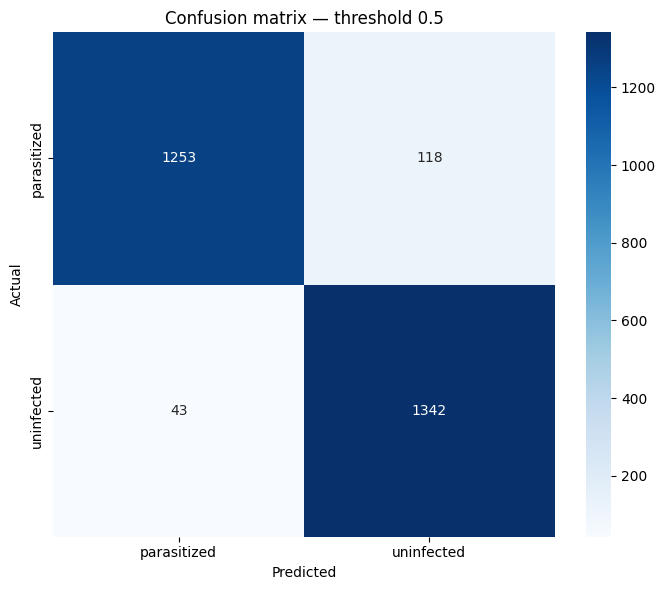

In [39]:
fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax,
)
ax.set_title(f"Confusion matrix — threshold {THRESHOLD}")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

fig.tight_layout()

run.log({
    "test/confusion_matrix": wandb.Image(fig)
})

plt.show()

## ROC Plots

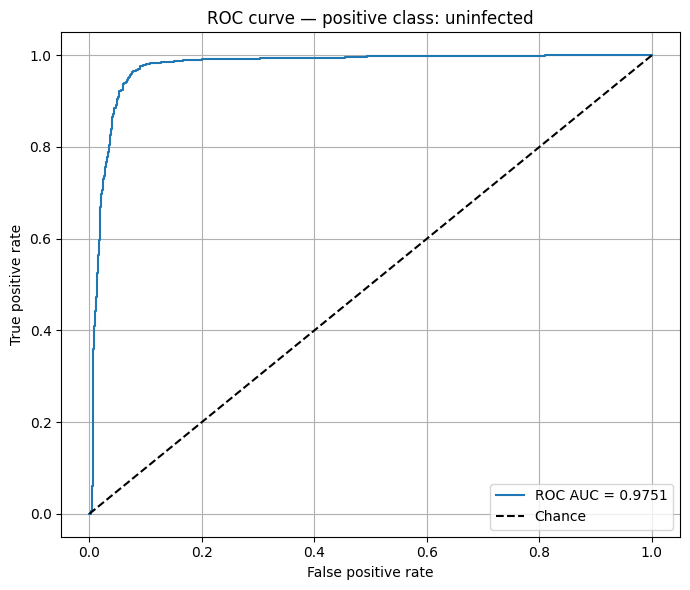

In [40]:
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_probability,
)
test_roc_auc = roc_auc_score(
    y_true,
    y_probability,
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {test_roc_auc:.4f}",
)
ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Chance",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(
    f"ROC curve — positive class: {CLASS_NAMES[1]}"
)
ax.legend()
ax.grid(True)
fig.tight_layout()

run.log({
    "test/roc_curve": wandb.Image(fig)
})

plt.show()

## Log Sample predictions to W&B

In [41]:
sample_images, sample_labels = next(iter(test_dataset))
sample_probabilities = lenet_model.predict(
    sample_images,
    verbose=0,
).reshape(-1)

sample_predictions = (
    sample_probabilities >= THRESHOLD
).astype(np.int32)

In [42]:
prediction_table = wandb.Table(
    columns=[
        "image",
        "actual_class",
        "predicted_class",
        "probability_class_1",
        "correct",
    ]
)

for i in range(min(9, len(sample_images))):
    actual_index = int(sample_labels[i].numpy().item())
    predicted_index = int(sample_predictions[i])

    image = np.clip(
        sample_images[i].numpy(),
        0,
        255,
    ).astype(np.uint8)

    prediction_table.add_data(
        wandb.Image(image),
        CLASS_NAMES[actual_index],
        CLASS_NAMES[predicted_index],
        float(sample_probabilities[i]),
        bool(actual_index == predicted_index),
    )

run.log({
    "test/sample_predictions": prediction_table
})

# Saving model in W&B

In [ ]:
model_artifact = wandb.Artifact(
    name=f"malaria-lenet-{run.id}",
    type="model",
    description="Malaria CNN selected using validation loss.",
    metadata={
        **CONFIGURATION,
        "class_names": CLASS_NAMES,
        "classification_threshold": THRESHOLD,
        "positive_class": CLASS_NAMES[1],
        "input_pixel_range": "0–255; rescaling is inside the model",
    },
)

model_artifact.add_file(best_model_path)

run.log_artifact(
    model_artifact,
    aliases=["best"],
)

In [43]:
run.finish()

epoch/accuracy,▁▆▇▇▇█████████
epoch/auc,▁▆▇▇▇█████████
epoch/epoch,▁▂▂▃▃▄▄▅▅▆▆▇▇█
epoch/fn,█▃▃▂▂▁▁▁▁▁▁▁▁▁
epoch/fp,█▃▂▂▂▂▁▁▁▁▁▁▁▁
epoch/learning_rate,████▂▂▂▁▁▁▁▁▁▁
epoch/loss,█▄▃▃▂▂▁▁▁▁▁▁▁▁
epoch/precision,▁▆▇▇▇█████████
epoch/recall,▁▆▆▇▇█████████
epoch/tn,▁▆▇▇▇▇████████
+20,...
